# 03 — Météo des carreaux

Téléchargement Open-Meteo (archive) par carreau, avec compteur d'appels et cache (`src/meteo.py`).

In [1]:
import sys
import tempfile
from pathlib import Path

_racine = Path.cwd()
while not (_racine / "src").exists() and _racine != _racine.parent:
    _racine = _racine.parent
if str(_racine) not in sys.path:
    sys.path.insert(0, str(_racine))

import pandas as pd
import matplotlib.pyplot as plt
from src import config
from src.bassins import charger_bassins, ForetBassins, localiser, carreaux_amont
from src.meteo import Meteo, cout_appel

HORAIRES = ["precipitation", "temperature_2m", "snow_depth", "shortwave_radiation", "rain",
            "soil_moisture_7_to_28cm", "snowfall", "et0_fao_evapotranspiration", "soil_moisture_28_to_100cm"]
JOURNALIERES = ["temperature_2m_max"]

## 1. Abonnement et quota

Abonnement lu dans `config.ABONNEMENT_OPEN_METEO`. Quota d'après le journal des appels (`data/cache/meteo/journal_appels.csv`).

In [2]:
m = Meteo()
print("abonnement :", m.abonnement)
m.etat_quota()

abonnement : gratuit


,utilise,limite,reste
fenetre,,,
minute,0.0,600,600.0
heure,0.0,5000,5000.0
jour,522.9,10000,9477.1
mois,29669.6,300000,270330.4


## 2. Coût d'une requête

Règle mesurée le 2026-10-06 : 1 appel = 10 variables × 14 jours pour 1 point, minimum 1 par point.

In [3]:
mesures = pd.DataFrame([
    ("1 point, 1 variable, 1 an", 1, 1, 365, 2.6),
    ("5 points, 1 variable, 1 an", 5, 1, 365, 13),
    ("1 point, 10 variables, 1 an", 1, 10, 365, 26),
    ("1 point, 20 variables, 1 an", 1, 20, 365, 52),
    ("1 point, 20 variables, 1 jour", 1, 20, 1, 2),
    ("1 point, 10 variables, 14 jours", 1, 10, 14, 1),
], columns=["requête", "points", "variables", "jours", "mesuré"])
mesures["calculé"] = [round(cout_appel(p, v, j), 1) for p, v, j in mesures[["points", "variables", "jours"]].values]
mesures

,requête,points,variables,jours,mesuré,calculé
0,"1 point, 1 variable, 1 an",1,1,365,2.6,2.6
1,"5 points, 1 variable, 1 an",5,1,365,13.0,13.0
2,"1 point, 10 variables, 1 an",1,10,365,26.0,26.1
3,"1 point, 20 variables, 1 an",1,20,365,52.0,52.1
4,"1 point, 20 variables, 1 jour",1,20,1,2.0,2.0
5,"1 point, 10 variables, 14 jours",1,10,14,1.0,1.0


## 3. Carreaux d'un bassin

Amont d'Espinasses (Durance, aval de Serre-Ponçon).

In [4]:
bassins = charger_bassins()
foret = ForetBassins.depuis_table(bassins)
zone = int(localiser([6.272764047], [44.470913176])[0])
carreaux = carreaux_amont(zone, foret)
print(f"{len(carreaux)} carreaux")
carreaux.head()

61 carreaux


,carreau,lon_centre,lat_centre,surface_km2,pourcentage
0,830767,6.558140,44.956062,86.012142,2.400657
1,833347,6.547988,44.885763,85.991154,2.400071
2,835933,6.816074,44.815465,85.966729,2.399389
3,835932,6.676971,44.815465,85.957155,2.399122
4,835931,6.537867,44.815465,85.945852,2.398807


## 4. Coût prévu, sans rien télécharger

Tous les carreaux, 10 variables, 25 ans.

In [5]:
m.cout_prevu(carreaux, HORAIRES, JOURNALIERES, "2000-01-01", "2024-12-31")

{'appels': 20551.7,
 'requetes': 41,
 'carreaux_a_telecharger': 38,
 'carreaux_complets_en_cache': 23}

## 5. Téléchargement

3 carreaux, 10 variables, juin 2023.

prévu : {'appels': 0, 'requetes': 0, 'carreaux_a_telecharger': 0, 'carreaux_complets_en_cache': 3}
{'horaire': (720, 27), 'journalier': (30, 3)}


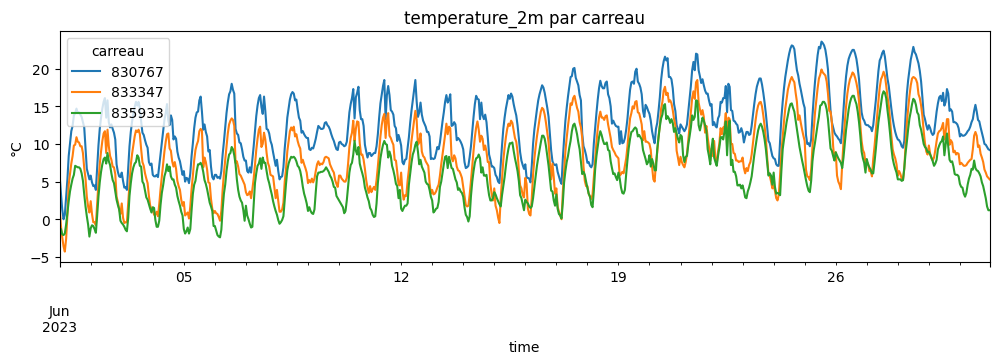

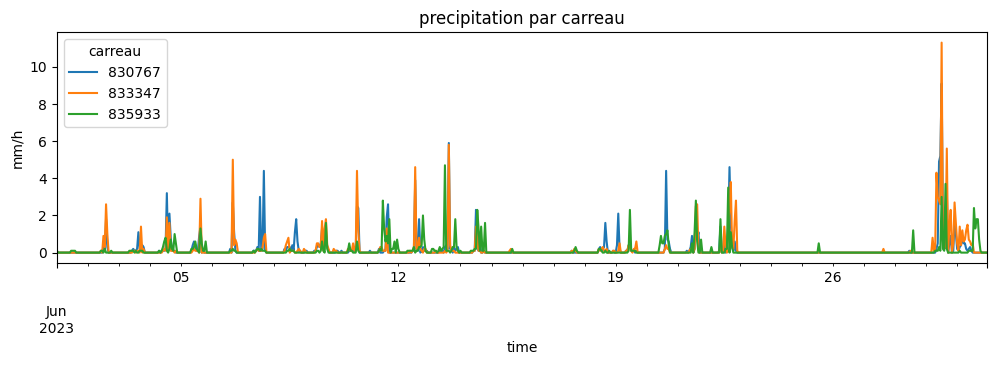

In [6]:
trois = carreaux.head(3)
print("prévu :", m.cout_prevu(trois, HORAIRES, JOURNALIERES, "2023-06-01", "2023-06-30"))
donnees = m.telecharger(trois, HORAIRES, JOURNALIERES, "2023-06-01", "2023-06-30")
print({res: df.shape for res, df in donnees.items()})
donnees["horaire"].xs("temperature_2m", axis=1, level="variable").plot(figsize=(12, 3), ylabel="°C", title="temperature_2m par carreau")
plt.show()
donnees["horaire"].xs("precipitation", axis=1, level="variable").plot(figsize=(12, 3), ylabel="mm/h", title="precipitation par carreau")
plt.show()

## 6. Cache

La même demande ne coûte plus rien ; contenu du cache ; quota après.

In [7]:
print("même demande, prévu :", m.cout_prevu(trois, HORAIRES, JOURNALIERES, "2023-06-01", "2023-06-30"))
m.contenu_cache()

même demande, prévu : {'appels': 0, 'requetes': 0, 'carreaux_a_telecharger': 0, 'carreaux_complets_en_cache': 3}


,carreau,variable,resolution,debut,fin,mo_carreau
0,825618,et0_fao_evapotranspiration,horaire,2000-01-01,2009-01-06,1.084
1,825618,precipitation,horaire,2000-01-01,2009-01-06,1.084
2,825618,rain,horaire,2000-01-01,2009-01-06,1.084
3,825618,shortwave_radiation,horaire,2000-01-01,2009-01-06,1.084
4,825618,snow_depth,horaire,2000-01-01,2009-01-06,1.084
...,...,...,...,...,...,...
405,848912,snowfall,horaire,2000-01-01,2009-01-06,1.058
406,848912,soil_moisture_28_to_100cm,horaire,2000-01-01,2009-01-06,1.058
407,848912,soil_moisture_7_to_28cm,horaire,2000-01-01,2009-01-06,1.058
408,848912,temperature_2m,horaire,2000-01-01,2009-01-06,1.058


In [8]:
m.etat_quota()

,utilise,limite,reste
fenetre,,,
minute,0.0,600,600.0
heure,0.0,5000,5000.0
jour,9804.0,10000,196.0
mois,19762.6,300000,280237.4


## 7. `vider_cache`

Sur un cache temporaire (1 carreau, 1 jour, 1 appel), pour ne pas toucher au vrai cache.

In [9]:
essai = Meteo(dossier=tempfile.mkdtemp())
essai.telecharger(carreaux.head(1), ["precipitation"], [], "2023-06-01", "2023-06-01")
print("avant :", len(essai.contenu_cache()), "ligne(s)")
essai.vider_cache()
print("après :", len(essai.contenu_cache()), "ligne(s)")

avant : 1 ligne(s)
après : 0 ligne(s)


## 8. Combien de valeurs faut-il vraiment ? (réduction de dimension)

X, la table d'entrée du modèle de débit, contient la météo de chaque carreau à chaque heure. Avant de choisir quoi y mettre, on mesure combien de valeurs **différentes** la météo contient vraiment : en espace (combien de carreaux suffisent) et en temps (à quel pas il faut la regarder).

Bassin de La Clapière (41 carreaux), données du cache uniquement (aucun appel).

**Attention, la source change le 1er janvier 2017.** Sans choix de modèle, l'archive Open-Meteo prend « le meilleur disponible » (vérifié le 2026-10-13 en comparant le cache à chaque modèle) :

| variable | avant 2017 | depuis 2017 |
|---|---|---|
| pluie, soleil | ERA5 (25 km) : chaque carreau recopie le point ERA5 le plus proche | ECMWF IFS 9 km (le modèle de nos prévisions) |
| température, humidité du sol | ERA5-Land (9 km) | ECMWF IFS 9 km |
| neige au sol | ERA5-Land (9 km) | ERA5-Land (9 km) |
| pluie seule, neige qui tombe, évapotranspiration | calculées par Open-Meteo (identiques à aucun modèle) | idem |

In [ ]:
import numpy as np

clap = carreaux_amont(int(localiser([6.498014], [44.55536])[0]), foret)
VARIABLES = {"precipitation": "précipitations (pluie + neige)", "rain": "pluie seule", "snowfall": "neige qui tombe",
             "temperature_2m": "température", "shortwave_radiation": "soleil", "et0_fao_evapotranspiration": "évapotranspiration",
             "snow_depth": "neige au sol", "soil_moisture_7_to_28cm": "humidité du sol 7-28 cm",
             "soil_moisture_28_to_100cm": "humidité du sol 28-100 cm"}       # toutes les variables horaires du cache
print(len(clap), "carreaux ; coût :", m.cout_prevu(clap, list(VARIABLES), [], "2001-01-01", "2025-12-31")["appels"], "appel(s)")
h = m.telecharger(clap, list(VARIABLES), [], "2001-01-01", "2025-12-31")["horaire"].astype(float)

### 8.1 En espace : combien de carreaux différents ?

Pour une variable, on range les 41 séries horaires côte à côte et on cherche les **motifs** communs (analyse en composantes principales) : le premier motif est la façon dont tous les carreaux varient ensemble, le suivant ce qui reste, etc. Si $\sigma_1^2 \ge \sigma_2^2 \ge \dots \ge \sigma_{41}^2$ sont les parts de variance de chaque motif, la part expliquée par les $k$ premiers est

$$
\frac{\sigma_1^2 + \dots + \sigma_k^2}{\sigma_1^2 + \dots + \sigma_{41}^2}.
$$

Première colonne : le nombre de motifs qu'il faut pour 95 % de la variance, c'est-à-dire le nombre de valeurs vraiment différentes sur le bassin (41 : chaque carreau compte ; 1 : une seule valeur suffit). Deuxième colonne : corrélation moyenne entre carreaux voisins (moins de 12 km). Période 2017-2025.

In [ ]:
x = np.radians(clap["lon_centre"].to_numpy()) * 6371 * np.cos(np.radians(clap["lat_centre"].mean()))
y = np.radians(clap["lat_centre"].to_numpy()) * 6371
haut = np.triu_indices(len(clap), 1)
voisins = np.hypot(x[:, None] - x[None], y[:, None] - y[None])[haut] < 12

def espace(M):
    part = np.cumsum(np.linalg.svd((M - M.mean()).to_numpy(), compute_uv=False) ** 2)
    return {"motifs pour 95 %": int(np.searchsorted(part / part[-1], 0.95) + 1),
            "ressemblance entre carreaux voisins": round(np.corrcoef(M.to_numpy().T)[haut][voisins].mean(), 2)}

pd.DataFrame.from_dict({fr: espace(h.xs(v, axis=1, level="variable").loc["2017":"2025"].dropna())
                        for v, fr in VARIABLES.items()}, orient="index")

### 8.2 En temps : à quel pas faut-il regarder la météo ?

On remplace chaque valeur horaire $x_t$ par la moyenne $\bar x_\Delta(t)$ du bloc de $\Delta$ heures qui la contient (blocs calés sur minuit UTC), et on mesure la part de la variance qui reste :

$$
\text{gardé}(\Delta) = 1 - \frac{\sum_t \left(x_t - \bar x_\Delta(t)\right)^2}{\sum_t \left(x_t - \bar x\right)^2}.
$$

Première colonne : le plus long pas $\Delta$ qui garde encore 95 % (moyenne sur les 41 carreaux). Deuxième colonne : corrélation moyenne entre deux heures qui se suivent. Période 2017-2025.

In [ ]:
PAS = [1, 2, 3, 4, 6, 8, 12, 24, 48, 72, 96, 168, 336, 720, 1440, 2160, 4320]

def lisible(p):
    return f"{p} h" if p < 24 else f"{p // 24} j"

def temps(M):
    X = M.to_numpy()
    total = ((X - X.mean(0)) ** 2).sum()
    garde_95 = 1
    for p in PAS[1:]:
        moy = M.groupby(np.arange(len(M)) // p).transform("mean").to_numpy()
        if 1 - ((X - moy) ** 2).sum() / total < 0.95:
            break
        garde_95 = p
    voisines = np.mean([np.corrcoef(X[1:, j], X[:-1, j])[0, 1] for j in range(X.shape[1])])
    return {"pas pour garder 95 %": lisible(garde_95), "ressemblance entre heures voisines": round(voisines, 2)}

pd.DataFrame.from_dict({fr: temps(h.xs(v, axis=1, level="variable").loc["2017":"2025"].dropna())
                        for v, fr in VARIABLES.items()}, orient="index")

### 8.3 À retenir (mesuré le 2026-10-13, La Clapière, 2017-2025)

**En espace**
- Température, soleil, évapotranspiration et neige au sol : une seule valeur pour tout le bassin garde 95 %.
- Humidité du sol : une dizaine de valeurs. Neige qui tombe : 10. Précipitations (pluie + neige) : 18 sur 41.
- La pluie seule est la plus détaillée (25 sur 41, voisins à 0,73 seulement) : la part qui tombe en pluie plutôt qu'en neige dépend de l'altitude de chaque carreau.
- Avant 2017, les précipitations n'ont de toute façon que 11 valeurs différentes sur les 41 carreaux : les 11 points ERA5 du bassin, recopiés.

**En temps**
- Précipitations, pluie seule et neige qui tombe : il faut l'heure. C'est la variance de la météo, pas forcément ce qui compte pour le débit : la rivière lisse, c'est à mesurer à part.
- Soleil et évapotranspiration : 2 h (surtout le cycle du jour, que l'heure en cos/sin dans X donne déjà). Température : 8 h.
- Neige au sol et humidité du sol : une valeur par semaine ou par quinzaine suffit. Les prendre à l'instant t suffit.
